# Fig. 1: state-space UMAP, all 18 sessions, 10 window features

Redraws the UMAP from its saved embedding (producer `fig1_state_space_umap_session.py`, `SESSION=all FSET=10`).

- **Embedding**: `fig1_state_umap_all18_10f.csv`: 9 132 non-overlapping 30 s windows, each inside one state; 18 sessions, 6 mice; features z-scored per session; UMAP Euclidean, n_neighbors 20, random_state 42.
- **d2** = d2 (2024 Euclidean, 40 ms, AR p = 20), a label, not a feature; z-scored within session by default.
- **SI**: PridaLab structure index in the 10-D feature space, all states, pooled over sessions; descriptive.
- **Test line**: per session, the all-state SI against its time-preserving null (d2 circularly shifted within each state episode, 500 surrogates; `fig1_si_sessions.csv`).

`REFIT_UMAP = True` refits UMAP on the saved features with `UMAP_KW`; output goes to `..._custom.png/.svg`.

In [2]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = os.path.abspath("")                      # revision
sys.path.insert(0, HERE)
from fig1_state_space_umap import FEATURES, STATE_COLOR, STATE_LABEL, LOGDIR, FIGDIR
from run_fig1_metrics import assert_local_path
%matplotlib inline

EMB = os.path.join(LOGDIR, "fig1_state_umap_all18_10f.csv")
SI_TEST = os.path.join(LOGDIR, "fig1_si_sessions.csv")

## Knobs
Everything visual is here; the cells below only read these.

In [3]:
# ---- what to compute -----------------------------------------------------------------------------
REFIT_UMAP = False          # True: refit UMAP on the saved z-scored features with UMAP_KW
UMAP_KW = dict(n_components=2, n_neighbors=20, min_dist=0.1, metric="euclidean", random_state=42)
COMPUTE_SI = True           # structure index in the 10-D feature space, all states; False hides it
SHOW_TEST = True           # the 'per session vs its own null' line in the d2 title

# ---- layout --------------------------------------------------------------------------------------
PANELS = ["state", "d2", "swr"]   # any subset, any order
FIGSIZE = (11.5, 3.9)
POINT_SIZE = 1.5
ALPHA = 1.0
RASTERIZE = True            # points rasterised inside the svg (small file; text stays editable)
SHOW_AXES = True            # False: no axis lines, no 'UMAP 1 / UMAP 2'
FONT, FONT_SIZE, TITLE_SIZE = "Arial", 9, 8
PANEL_LETTERS = True
SHOW_SUPTITLE = True
SHOW_FOOTNOTE = True

# ---- state panel ---------------------------------------------------------------------------------
STATE_DRAW_ORDER = ["NREM", "nonTHETA", "REM", "THETA"]   # later = drawn on top
STATE_COLORS = dict(STATE_COLOR)                          # e.g. STATE_COLORS["REM"] = "#c994c7"
LEGEND_LOC, LEGEND_MARKERSCALE, LEGEND_FONTSIZE = "upper center", 8, 7

# ---- d2 panel ------------------------------------------------------------------------------------
D2_COL = "d2_z"             # "d2_z" (z within session) or "d2" (raw: mixes unit-yield offsets between sessions)
D2_CMAP = "viridis"
D2_VMIN, D2_VMAX = -2.0, 2.0
D2_SORT = None              # None: file order; "asc": high values drawn on top; "desc": low values on top

# ---- SWR panel -----------------------------------------------------------------------------------
SWR_CMAP = "magma"
SWR_VMIN, SWR_VMAX = 0.0, None
SWR_SORT = None

# ---- output --------------------------------------------------------------------------------------
SAVE = True
OUT = os.path.join(FIGDIR, "fig1_state_umap_all18_10f_custom")
DPI = 300

## Embedding

In [4]:
D = pd.read_csv(EMB)
if REFIT_UMAP:
    import umap
    t0 = time.time()
    D[["u1", "u2"]] = umap.UMAP(**UMAP_KW).fit_transform(D[FEATURES].to_numpy(float))
    print(f"UMAP refit in {time.time() - t0:.0f} s")
print(f"{len(D)} windows, {D.session.nunique()} sessions, {D.animal.nunique()} mice;",
      D.state.value_counts().to_dict())

9132 windows, 18 sessions, 6 mice; {'NREM': 6042, 'nonTHETA': 2632, 'THETA': 231, 'REM': 227}


## Structure index and the all-state test (for the titles)

In [5]:
# SI of each label in the 10-D feature space, all states together (n_neighbors 20, 10 bins, as the pupil paper's
# all-state SI), pooled over the sessions in the figure: descriptive. The test is per session, in fig1_si_sessions.
SI = {}
if COMPUTE_SI:
    from fig1_lfp_manifold import SI_PATH
    sys.path.insert(0, SI_PATH)
    from structure_index import compute_structure_index
    X = D[FEATURES].to_numpy(float)
    for lab, col in (("d2", D2_COL), ("swr", "ripple_rate_hz")):
        SI[lab] = float(compute_structure_index(X, D[col].to_numpy(float).copy(), n_bins=10, n_neighbors=20,
                                                num_shuffles=0, verbose=False)[0])
        print(f"SI {lab} ({col}), all states, 10-D feature space: {SI[lab]:.3f}")

TEST_NOTE = ""
if SHOW_TEST and os.path.exists(SI_TEST):
    R = pd.read_csv(SI_TEST)
    R = R[R.session.isin(D.session.unique())]
    if set(R.session) == set(D.session):          # a test run on fewer sessions than the figure is not quoted
        TEST_NOTE = (f"per session vs its own time-shift null:\n"
                     f"{int((R.SI > R.null_p95).sum())}/{len(R)} sessions above")
print(TEST_NOTE or "(no test covering every session in the figure)")

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SI d2 (d2_z), all states, 10-D feature space: 0.224
SI swr (ripple_rate_hz), all states, 10-D feature space: 0.644
per session vs its own time-shift null:
18/18 sessions above


## Figure

-> D:\Documents\GitHub\Sleep_criticaltiy\reports\revision_figs\fig1_state_umap_all18_10f_custom.png


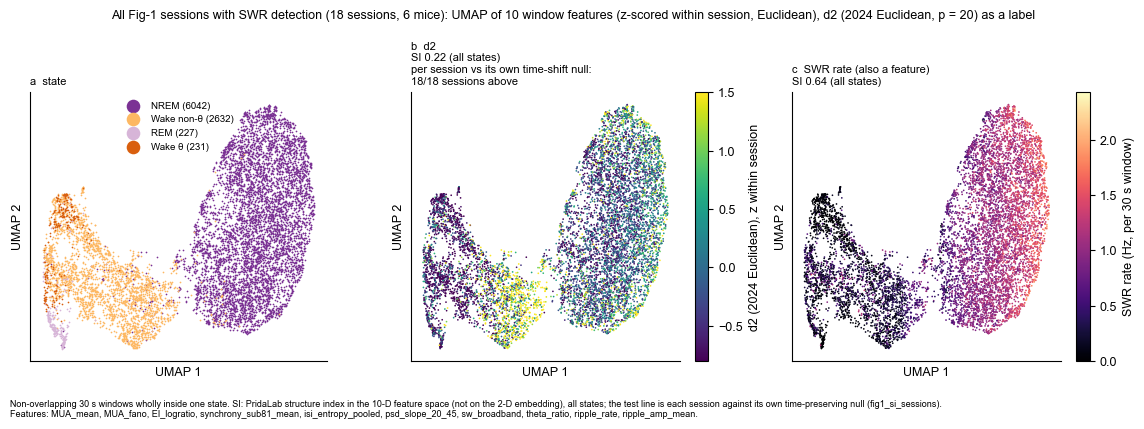

In [9]:
plt.rcParams.update({"font.family": FONT, "font.size": FONT_SIZE, "svg.fonttype": "none",
                     "axes.spines.top": False, "axes.spines.right": False})


def ordered(col, how):
    return D if how is None else D.sort_values(col, ascending=(how == "asc"))


def draw_state(ax):
    for st in STATE_DRAW_ORDER:
        g = D[D.state == st]
        if len(g):
            ax.scatter(g.u1, g.u2, s=POINT_SIZE, c=STATE_COLORS[st], alpha=ALPHA, lw=0, rasterized=RASTERIZE,
                       label=f"{STATE_LABEL[st]} ({len(g)})")
    ax.legend(frameon=False, fontsize=LEGEND_FONTSIZE, markerscale=LEGEND_MARKERSCALE, loc=LEGEND_LOC)
    return "state"


def draw_d2(ax):
    g = ordered(D2_COL, D2_SORT)
    h = ax.scatter(g.u1, g.u2, s=POINT_SIZE, c=g[D2_COL], cmap=D2_CMAP, vmin=-0.8, vmax=1.5,
                   alpha=ALPHA, lw=0, rasterized=RASTERIZE)
    plt.colorbar(h, ax=ax, fraction=0.046,
                 label="d2 (2024 Euclidean), z within session" if D2_COL == "d2_z" else "d2 (2024 Euclidean)")
    title = "d2"
    if "d2" in SI:
        title += f"\nSI {SI['d2']:.2f} (all states)"
    if TEST_NOTE:
        title += "\n" + TEST_NOTE
    return title


def draw_swr(ax):
    g = ordered("ripple_rate_hz", SWR_SORT)
    h = ax.scatter(g.u1, g.u2, s=POINT_SIZE, c=g.ripple_rate_hz, cmap=SWR_CMAP, vmin=SWR_VMIN, vmax=SWR_VMAX,
                   alpha=ALPHA, lw=0, rasterized=RASTERIZE)
    plt.colorbar(h, ax=ax, fraction=0.046, label="SWR rate (Hz, per 30 s window)")
    title = "SWR rate (also a feature)"
    if "swr" in SI:
        title += f"\nSI {SI['swr']:.2f} (all states)"
    return title


DRAW = {"state": draw_state, "d2": draw_d2, "swr": draw_swr}
fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, squeeze=False)
for i, (ax, p) in enumerate(zip(axes[0], PANELS)):
    title = DRAW[p](ax)
    ax.set_title((f"{'abcdef'[i]}  " if PANEL_LETTERS else "") + title, loc="left", fontsize=TITLE_SIZE)
    ax.set_xticks([]); ax.set_yticks([])
    if SHOW_AXES:
        ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
    else:
        ax.axis("off")
if SHOW_SUPTITLE:
    fig.suptitle(f"All Fig-1 sessions with SWR detection ({D.session.nunique()} sessions, {D.animal.nunique()} mice): "
                 f"UMAP of {len(FEATURES)} window features (z-scored within session, Euclidean), "
                 "d2 (2024 Euclidean, p = 20) as a label", fontsize=FONT_SIZE)
if SHOW_FOOTNOTE:
    fig.text(0.01, -0.02,
             "Non-overlapping 30 s windows wholly inside one state. SI: PridaLab structure index in the 10-D feature space "
             "(not on the 2-D embedding), all states; the test line is each session against its own time-preserving null "
             f"(fig1_si_sessions).\nFeatures: {', '.join(FEATURES)}.", fontsize=6.5, va="top")
fig.tight_layout()
if SAVE:
    for ext in ("png", "svg"):
        fig.savefig(assert_local_path(f"{OUT}.{ext}"), dpi=DPI, bbox_inches="tight")
    print("->", OUT + ".png")
plt.show()